In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 13.4 — Dual and tensor-product actions

Source: SMSA version 7.8 (2026-11-05), `smsa.pdf`, pp. 280–282, (13.25)–(13.32), with the enveloping-algebra coproduct from §15.2. This notebook translates the named formulas; it does not replace their discussion in SMSA. Native DisCoPy figures below read **top to bottom**, whereas SMSA reads bottom to top. Tensor factors retain their left-to-right order. `f >> g` means $g\circ f$. Tensor arrays list input axes before output axes; a conventional column matrix is supplied transposed. Checks print computed objects and comparisons and continue on a failed equality.

For a fixed Lie-algebra element $H$, (13.27) is the sum of two terms: $H$ acts on the first factor or on the second factor. We first display these two terms, then evaluate the dual action and the coproduct diagram.

In [1]:
from discopy import symmetric, tensor
import numpy as np

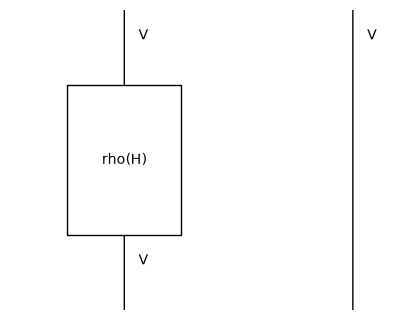

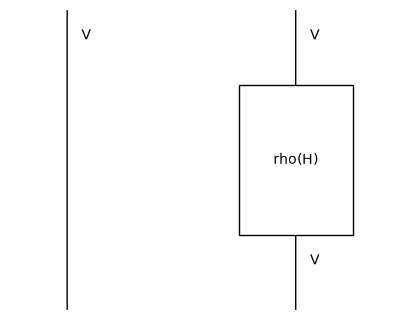

In [2]:
V = symmetric.Ty('V')
h = symmetric.Box('rho(H)', V, V)
left_term = h @ symmetric.Id(V)
right_term = symmetric.Id(V) @ h
left_term.draw(figsize=(4,3))
right_term.draw(figsize=(4,3))

In [3]:
H = np.array([[1,0],[0,-1]])
F = tensor.Functor({V: tensor.Dim(2)}, {h: H.T}, dom=symmetric.Category, dtype=int)
action = F(left_term) + F(right_term)
print('(13.27): column matrix in basis 00,01,10,11')
print(action.array.reshape(4,4).T)
print('expected diagonal = [2,0,0,-2]')
print('difference =', action.array.reshape(4,4).T-np.diag([2,0,0,-2]))
print('equal =', np.array_equal(action.array.reshape(4,4).T, np.diag([2,0,0,-2])))

(13.27): column matrix in basis 00,01,10,11
[[ 2  0  0  0]
 [ 0  0  0  0]
 [ 0  0  0  0]
 [ 0  0  0 -2]]
expected diagonal = [2,0,0,-2]
difference = [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
equal = True


### A complex example of the dual action

Choose $X=\left(\begin{smallmatrix}1&i\\0&-1\end{smallmatrix}\right)\in\mathfrak{sl}_2(\mathbb C)$, the covector $f=(1+i,2)$ and $v=(2,1-i)^t$. These numbers are chosen for this example. In (13.25)–(13.26), $\rho^+(X)=-X^t$, and $[\rho^+(X)f](v)=-f(Xv)$. The pairing is bilinear. Native transpose bends the input and output $V$ wires to form the map on the left dual $V^\ast$; the scalar coupon supplies the minus sign. The displayed composite evaluates the left side. A negative adjoint introduces complex conjugation and gives a different answer here.


(13.26): computed column matrix, expected -X.T
[[-1.+0.j  0.+0.j]
 [ 0.-1.j  1.+0.j]]
[[-1.-0.j -0.-0.j]
 [-0.-1.j  1.-0.j]]
equal = True
(13.25): left side, right side, independent -f(Xv)
-6j -6j -6j
equal = True
negative-adjoint control = -2j
control differs = True


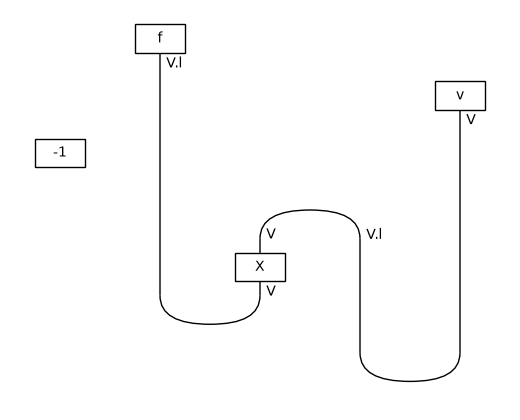

In [4]:
# SMSA 7.8, p. 280, (13.25)–(13.26): chosen complex dual-action example.
from discopy import rigid
D = rigid.Ty('V')
x = rigid.Box('X', D, D)
minus = rigid.Box('-1', rigid.Ty(), rigid.Ty())
f = rigid.Box('f', rigid.Ty(), D.l)
v = rigid.Box('v', rigid.Ty(), D)
dual_action = minus @ x.transpose(left=True)
pairing = rigid.Cup(D.l, D)
dual_lhs = (f @ v) >> (dual_action @ rigid.Id(D)) >> pairing
dual_rhs = (minus @ f @ v) >> (rigid.Id(D.l) @ x) >> pairing
adjoint_control = rigid.Box('-X dagger', D.l, D.l)
wrong_dual_lhs = (f @ v) >> (adjoint_control @ rigid.Id(D)) >> pairing
X = np.array([[1, 1j], [0, -1]], dtype=complex)
f_values = np.array([1 + 1j, 2])
v_values = np.array([2, 1 - 1j])
F_dual = tensor.Functor(
    {D: tensor.Dim(2)},
    {x: X.T, minus: -1, f: f_values, v: v_values,
     adjoint_control: (-X.conj().T).T}, dom=rigid.Category, dtype=complex)
dual_lhs.draw(figsize=(5, 4))
print('(13.26): computed column matrix, expected -X.T')
print(F_dual(dual_action).array.T)
print(-X.T)
print('equal =', np.array_equal(F_dual(dual_action).array.T, -X.T))
print('(13.25): left side, right side, independent -f(Xv)')
print(F_dual(dual_lhs).array, F_dual(dual_rhs).array, -f_values @ X @ v_values)
print('equal =', np.array_equal(F_dual(dual_lhs).array, F_dual(dual_rhs).array))
print('negative-adjoint control =', F_dual(wrong_dual_lhs).array)
print('control differs =', not np.array_equal(F_dual(wrong_dual_lhs).array, F_dual(dual_lhs).array))


### Keeping the coproduct wire in (13.32)

Use the finite subcoalgebra $K=\operatorname{span}(1,H,H^2)\subset U(\mathfrak{sl}_2)$, with the displayed ordered basis. The coproduct restricts to
$$\Delta(1)=1\otimes1,\qquad \Delta(H)=H\otimes1+1\otimes H,$$
$$\Delta(H^2)=H^2\otimes1+2H\otimes H+1\otimes H^2.$$
The action on $V=\mathbb C^2$ has slices $I,H,H^2$, where $H=\operatorname{diag}(1,-1)$. Although $H^2$ acts as $I$ on this $V$, $1$ and $H^2$ are distinct basis elements of $K$. On two spins, their actions differ: $1$ acts as $I_4$, whereas $H^2$ acts as $\operatorname{diag}(4,0,0,4)$. This $K$ is a subcoalgebra, not an algebra or a truncated enveloping algebra.

The first picture distributes the input from $K$ with $\Delta$, swaps the middle two wires, then acts on each copy of $V$. The second picture is a single action coupon with independently supplied slices $I_4,T,T^2$, where $T=H\otimes I+I\otimes H=\operatorname{diag}(2,0,0,-2)$. We compare every coefficient, so equality holds for every input in $K\otimes V\otimes V$ by linearity. This is a finite restriction of (13.32); it does not implement the whole enveloping algebra.


(13.32): actual and expected types
K @ V @ V -> V @ V
K @ V @ V -> V @ V
types equal = True
computed array (input axes K,V,V; output axes V,V) =
[[[[[ 1  0]
    [ 0  0]]

   [[ 0  1]
    [ 0  0]]]


  [[[ 0  0]
    [ 1  0]]

   [[ 0  0]
    [ 0  1]]]]



 [[[[ 2  0]
    [ 0  0]]

   [[ 0  0]
    [ 0  0]]]


  [[[ 0  0]
    [ 0  0]]

   [[ 0  0]
    [ 0 -2]]]]



 [[[[ 4  0]
    [ 0  0]]

   [[ 0  0]
    [ 0  0]]]


  [[[ 0  0]
    [ 0  0]]

   [[ 0  0]
    [ 0  4]]]]]
independently supplied array =
[[[[[ 1  0]
    [ 0  0]]

   [[ 0  1]
    [ 0  0]]]


  [[[ 0  0]
    [ 1  0]]

   [[ 0  0]
    [ 0  1]]]]



 [[[[ 2  0]
    [ 0  0]]

   [[ 0  0]
    [ 0  0]]]


  [[[ 0  0]
    [ 0  0]]

   [[ 0  0]
    [ 0 -2]]]]



 [[[[ 4  0]
    [ 0  0]]

   [[ 0  0]
    [ 0  0]]]


  [[[ 0  0]
    [ 0  0]]

   [[ 0  0]
    [ 0  4]]]]]
all coefficients equal = True


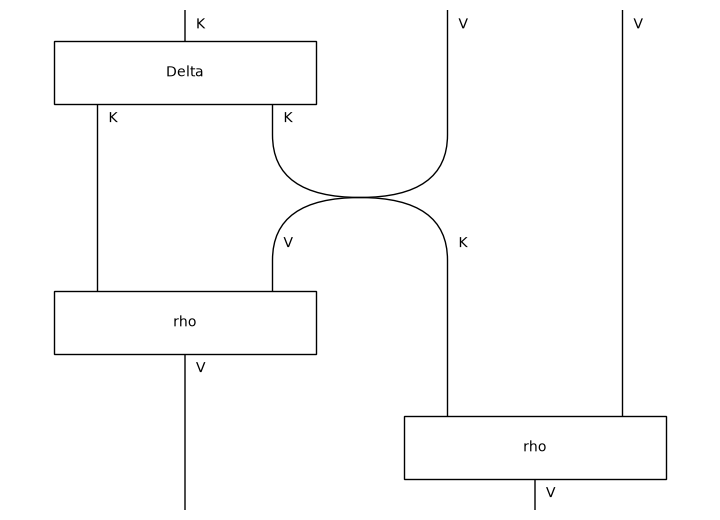

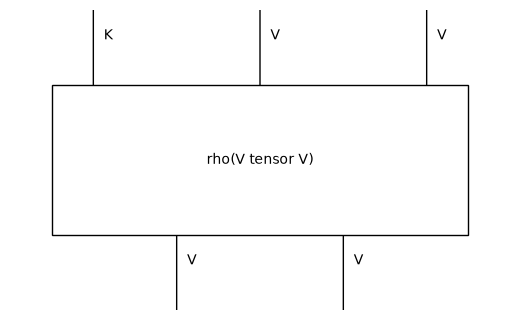

In [5]:
# SMSA 7.8, p. 282, (13.32), interpreted with the coproduct of §15.2.
K = symmetric.Ty('K')
Delta = symmetric.Box('Delta', K, K @ K)
rho = symmetric.Box('rho', K @ V, V)
tensor_action = ((Delta @ symmetric.Id(V @ V))
                 >> (symmetric.Id(K) @ symmetric.Swap(K, V) @ symmetric.Id(V))
                 >> (rho @ rho))
expected_action = symmetric.Box('rho(V tensor V)', K @ V @ V, V @ V)
Delta_values = np.zeros((3, 3, 3), dtype=int)
Delta_values[0, 0, 0] = 1
Delta_values[1, 1, 0] = Delta_values[1, 0, 1] = 1
Delta_values[2, 2, 0] = Delta_values[2, 0, 2] = 1
Delta_values[2, 1, 1] = 2
rho_values = np.stack([np.eye(2, dtype=int), H.T, (H @ H).T])
T = np.diag([2, 0, 0, -2])
expected_slices = np.stack([np.eye(4, dtype=int), T.T, (T @ T).T])
F_coproduct = tensor.Functor(
    {K: tensor.Dim(3), V: tensor.Dim(2)},
    {Delta: Delta_values, rho: rho_values,
     expected_action: expected_slices.reshape(3, 2, 2, 2, 2)},
    dom=symmetric.Category, dtype=int)
tensor_action.draw(figsize=(7, 5))
expected_action.draw(figsize=(5, 3))
coproduct_array = F_coproduct(tensor_action).array
expected_array = F_coproduct(expected_action).array
print('(13.32): actual and expected types')
print(tensor_action.dom, '->', tensor_action.cod)
print(expected_action.dom, '->', expected_action.cod)
print('types equal =', tensor_action.dom == expected_action.dom and tensor_action.cod == expected_action.cod)
print('computed array (input axes K,V,V; output axes V,V) =')
print(coproduct_array)
print('independently supplied array =')
print(expected_array)
print('all coefficients equal =', np.array_equal(coproduct_array, expected_array))


For $H^2$, the cross term has coefficient $2$. Dropping it changes the action on $V\otimes V$. The control below changes only that coefficient and prints the two resulting matrices.


In [6]:
wrong_Delta_values = Delta_values.copy()
wrong_Delta_values[2, 1, 1] = 0
F_wrong_coproduct = tensor.Functor(
    {K: tensor.Dim(3), V: tensor.Dim(2)},
    {Delta: wrong_Delta_values, rho: rho_values},
    dom=symmetric.Category, dtype=int)
wrong_coproduct_array = F_wrong_coproduct(tensor_action).array
print('correct H squared slice, as a column matrix =')
print(coproduct_array[2].reshape(4, 4).T)
print('slice after dropping 2 H tensor H =')
print(wrong_coproduct_array[2].reshape(4, 4).T)
print('control differs =', not np.array_equal(wrong_coproduct_array[2], expected_array[2]))


correct H squared slice, as a column matrix =
[[4 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 4]]
slice after dropping 2 H tensor H =
[[2 0 0 0]
 [0 2 0 0]
 [0 0 2 0]
 [0 0 0 2]]
control differs = True
